In [ ]:
# В этом файле я создавал пайплайн, который потом перенес в мейн

In [12]:
%load_ext autoreload
%autoreload 2

In [61]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
from tqdm import tqdm
import matplotlib.pyplot as plt
import xgboost, lightgbm, catboost

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

import config as cnf 
import utils as utl
import DeepLearning as DL

In [84]:
df_train['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [85]:
df_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


### Вывод

In [122]:
df_train = pd.read_csv(cnf.path['train_path'])
df_test = pd.read_csv(cnf.path['test_path'])

# Подготовка данных
X, X_ohe, y, X_test, X_ohe_test = utl.dataset_forming(df_train, df_test)

# Подготовка параметров
combo_param = utl.parametrs(cnf.RandomForestParam)
combo_param += utl.parametrs(cnf.DLParam)
combo_param += utl.parametrs(cnf.LogRegParam)
combo_param += utl.parametrs(cnf.KNNParam)
combo_param += utl.parametrs(cnf.DecisionTreeParam)
combo_param += utl.parametrs(cnf.CatBoostParam)
combo_param += utl.parametrs(cnf.LGBMParam)
combo_param += utl.parametrs(cnf.XGBoostParam)

if cnf.mode == 'validation':
    # Подготовка кросс валидации
    results = []
    dl_curves = [] 
    SK_Fold = StratifiedKFold(n_splits=cnf.n_splits, shuffle=True, random_state=cnf.random_state)

    for combo in combo_param:

        params = combo.copy()
        name_model = params.pop('name_model')
        use_scaler = params.pop('use_scaler')
        use_category = params.pop('use_category')

        # Флаг на категориальные признаки - если False, делаем OneHotCoding
        X_cur = X if use_category else X_ohe

        array_train_accuracy = []
        array_val_accuracy = []

        # Запускаем DL
        if name_model == 'nn_model':

            for i, (train_index, val_index) in enumerate(SK_Fold.split(X, y)):

                # Объявляем модель
                loss_model = nn.CrossEntropyLoss()
                torch.manual_seed(cnf.random_state)

                model = DL.nn_model(X_cur.shape[1])
                opt = torch.optim.Adam(model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
                scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                                                                opt
                                                                , mode=params['mode']
                                                                , factor=params['factor']
                                                                , patience=params['patience']
                                                                , threshold=params['threshold']
                                                                , min_lr=params['min_lr']
                                                                )

                # Подготовка данных для обучения
                X_train, y_train, X_val, y_val = utl.preparation_train(X_cur, y, train_index, val_index, use_scaler)

                tensor_X_train = torch.tensor(X_train, dtype=torch.float32)
                tensor_X_val  = torch.tensor(X_val,  dtype=torch.float32)
                tensor_y_train = torch.tensor(y_train.values, dtype=torch.long)
                tensor_y_val  = torch.tensor(y_val.values,  dtype=torch.long)

                dataset = TensorDataset(tensor_X_train, tensor_y_train)
                dataloader = DataLoader(dataset, batch_size=params['batch_size'], shuffle=True, drop_last=True)

                train_loop = tqdm(range(params['EPOCHS']))
                for epoch in train_loop:

                    model.train()

                    for _, val in enumerate(dataloader):
                    
                        # Прямой проход
                        pred = model(val[0])
                        loss = loss_model(pred, val[1])

                        # Обратный проход
                        opt.zero_grad()
                        loss.backward()

                        # Шаг оптимизации
                        opt.step()

                    model.eval()

                    # Считаем на валидации
                    with torch.no_grad():
                        # Считаем предсказания
                        pred_train = model(tensor_X_train)
                        pred_val = model(tensor_X_val)

                        # Считаем лосс
                        loss_train = loss_model(pred_train, tensor_y_train)
                        loss_val = loss_model(pred_val, tensor_y_val)

                        # Считаем точность на трейне
                        train_loss = loss_train.item()
                        true_answer = (pred_train.argmax(dim=1) == tensor_y_train).sum().item()
                        train_accuracy = true_answer / len(tensor_X_train)

                        # Считаем точность на тесте
                        val_loss = loss_val.item()
                        true_answer = (pred_val.argmax(dim=1) == tensor_y_val).sum().item()
                        val_accuracy = true_answer / len(tensor_X_val)

                    train_loop.set_description(f"Epoch [{epoch+1}/{params['EPOCHS']}], train_loss={train_loss:2f}, train_accuracy={train_accuracy:2f}, val_loss={val_loss:2f} val_accuracy={val_accuracy:2f} lr={scheduler.get_last_lr()[0]}")

                    scheduler.step(train_loss)


                    dl_curves.append({

                        'name_model': name_model
                        , 'Fold': i
                        , 'epoch': epoch
                        , 'train_accuracy': train_accuracy  
                        , 'train_loss': train_loss
                        , 'val_accuracy': val_accuracy
                        , 'val_loss': val_loss
                        , 'lr': opt.param_groups[0]['lr']
                        , 'combo': f"weight_decay={params['weight_decay']}, factor={params['factor']}"
                    })

                array_train_accuracy.append(train_accuracy)   # значение последней эпохи
                array_val_accuracy.append(val_accuracy)


        # Запускаем линейные модели и деревья
        else:     

            model = cnf.models[name_model](**params)
            
            train_loop = tqdm(enumerate(SK_Fold.split(X, y)))
            for i, (train_index, val_index) in train_loop:
                
                # Подготовка данных для обучения
                X_train, y_train, X_val, y_val = utl.preparation_train(X_cur, y, train_index, val_index, use_scaler)

                model_clone = clone(model)
                model_clone.fit(X_train, y_train)

                train_accuracy = model_clone.score(X_train, y_train)
                val_accuracy = model_clone.score(X_val, y_val)

                array_train_accuracy.append(train_accuracy)
                array_val_accuracy.append(val_accuracy)
                
                mean_train_accuracy = float(np.mean(array_train_accuracy))
                mean_train_std = float(np.std(array_train_accuracy))
                mean_val_accuracy = float(np.mean(array_val_accuracy))
                mean_val_std = float(np.std(array_val_accuracy))
                
                train_loop.set_description(f"SK_Fold [{i+1}/{cnf.n_splits}], model {name_model}, train_accuracy={mean_train_accuracy:2f}, val_accuracy={mean_val_accuracy:2f}")

        # Переименовываем параметры в Катбусте
        combo_row = {cnf.rename_params.get(k, k): v for k, v in combo.items()}

        results.append({
            **combo_row
            , 'train_accuracy'  :   mean_train_accuracy
            , 'train_std'       :   mean_train_std
            , 'val_accuracy'   :   mean_val_accuracy
            , 'val_std'        :   mean_val_std
        })
    
    
    
submissions = pd.DataFrame({'PassengerId': df_test['PassengerId']})
results_test = []

if cnf.mode == 'inference':
    
    for k, combo in enumerate(combo_param):
        params = combo.copy()
        name_model = params.pop('name_model')
        use_scaler = params.pop('use_scaler')
        use_category = params.pop('use_category')
        
        if name_model == 'nn_model':
            
            X_fit, X_pred = utl.preparation_inference(
                                X if use_category else X_ohe,
                                X_test if use_category else X_ohe_test,
                                use_scaler)
            
            tensor_X_fit  = torch.tensor(np.asarray(X_fit,  dtype=np.float32))
            tensor_X_pred = torch.tensor(np.asarray(X_pred, dtype=np.float32))
            tensor_y      = torch.tensor(y.values, dtype=torch.long)
            
            
            # Объявляем модель
            loss_model = nn.CrossEntropyLoss()
            torch.manual_seed(cnf.random_state)

            model = DL.nn_model(X_fit.shape[1])
            opt = torch.optim.Adam(model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                                                            opt
                                                            , mode=params['mode']
                                                            , factor=params['factor']
                                                            , patience=params['patience']
                                                            , threshold=params['threshold']
                                                            , min_lr=params['min_lr']
                                                            )


            dataset = TensorDataset(tensor_X_fit, tensor_y)
            dataloader = DataLoader(dataset, batch_size=params['batch_size'], shuffle=True, drop_last=True)

            train_loop = tqdm(range(params['EPOCHS']))
            for epoch in train_loop:

                model.train()

                for _, val in enumerate(dataloader):
                    
                    # Прямой проход
                    pred = model(val[0])
                    loss = loss_model(pred, val[1])

                    # Обратный проход
                    opt.zero_grad()
                    loss.backward()

                    # Шаг оптимизации
                    opt.step()

                model.eval()

                # Считаем на валидации
                with torch.no_grad():
                    # Считаем предсказания
                    pred_train = model(tensor_X_fit)

                    # Считаем лосс
                    loss_train = loss_model(pred_train, tensor_y)

                    # Считаем точность на трейне
                    train_loss = loss_train.item()
                    true_answer = (pred_train.argmax(dim=1) == tensor_y).sum().item()
                    train_accuracy = true_answer / len(tensor_X_fit)

                train_loop.set_description(f"Epoch [{epoch+1}/{params['EPOCHS']}], train_loss={train_loss:2f}, train_accuracy={train_accuracy:2f}, lr={scheduler.get_last_lr()[0]}")

                scheduler.step(train_loss)


                dl_curves.append({
                    'name_model': name_model
                    , 'Fold': i
                    , 'epoch': epoch
                    , 'train_accuracy': train_accuracy  
                    , 'train_loss': train_loss
                    , 'val_accuracy': val_accuracy
                    , 'val_loss': val_loss
                    , 'lr': opt.param_groups[0]['lr']
                    , 'combo': f"weight_decay={params['weight_decay']}, factor={params['factor']}"
                })

            model.eval()
            with torch.no_grad():
                train_accuracy = (model(tensor_X_fit).argmax(dim=1) == tensor_y).float().mean().item()
                answer = model(tensor_X_pred).argmax(dim=1).numpy()
            
            
            col = f'{name_model}_{k}'
            submissions[col] = answer
            combo_row = {cnf.rename_params.get(kk, kk): v for kk, v in combo.items()}
            results_test.append({**combo_row, 'col': col, 'train_accuracy': train_accuracy})           
            
        
        else:
            # Флаг на категориальные признаки - если False, делаем OneHotCoding
            X_fit, X_pred = utl.preparation_inference(
                                X if use_category else X_ohe,
                                X_test if use_category else X_ohe_test,
                                use_scaler)

            model = cnf.models[name_model](**params)

            model = clone(cnf.models[name_model](**params)).fit(X_fit, y)
            train_accuracy = model.score(X_fit, y)

            col = f'{name_model}_{k}'
            submissions[col] = model.predict(X_pred)   


            combo_row = {cnf.rename_params.get(kk, kk): v for kk, v in combo.items()}

            results_test.append({
                    **combo_row
                    , 'col': col
                    , 'train_accuracy'  :   train_accuracy
                })

Epoch [100/100], train_loss=0.349996, train_accuracy=0.854097, lr=9.765625e-07: 100%|██████████| 100/100 [00:03<00:00, 27.52it/s]


In [123]:
submissions

,PassengerId,RandomForest_0,nn_model_1,LogReg_2,LogReg_3,LogReg_4,KNN_5,KNN_6,DecisionTree_7,CatBoost_8,LGBM_9,XGBoost_10
0,892,0,0,0,0,0,0,0,0,0,0,0
1,893,0,0,0,0,0,0,0,0,0,0,0
2,894,0,0,0,0,0,0,0,0,0,0,0
3,895,0,0,0,0,0,0,0,0,0,0,0
4,896,0,0,0,1,1,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,0,0,0,0,0,0,0,0,0,0
414,1306,1,1,1,1,1,1,1,1,1,1,1
415,1307,0,0,0,0,0,0,0,0,0,0,0
416,1308,0,0,0,0,0,0,0,0,0,0,0


In [124]:
pd.DataFrame(results_test)

,max_depth,max_features,min_samples_leaf,n_estimators,name_model,random_state,use_category,use_scaler,col,train_accuracy,...,criterion,allow_writing_files,cat_features,reg_lambda,learning_rate,verbose,num_leaves,enable_categorical,min_child_weight,subsample
0,10.0,0.5,2.0,200.0,RandomForest,42.0,False,False,RandomForest_0,0.915825,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,nn_model,42.0,False,True,nn_model_1,0.854097,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,LogReg,42.0,False,True,LogReg_2,0.782267,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,LogReg,42.0,False,True,LogReg_3,0.810325,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,LogReg,42.0,False,True,LogReg_4,0.800224,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,KNN,NaN,False,True,KNN_5,0.849607,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,KNN,NaN,False,True,KNN_6,0.848485,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8.0,NaN,5.0,NaN,DecisionTree,42.0,False,False,DecisionTree_7,0.874299,...,gini,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,6.0,NaN,NaN,300.0,CatBoost,42.0,True,False,CatBoost_8,0.929293,...,NaN,False,"(Sex, Embarked)",3.0,0.10,0.0,NaN,NaN,NaN,NaN
9,NaN,NaN,20.0,100.0,LGBM,42.0,True,False,LGBM_9,0.893378,...,NaN,NaN,NaN,NaN,0.10,-1.0,8.0,NaN,NaN,NaN


In [42]:
results = pd.DataFrame(results)
results['gap'] = results['train_accuracy'] - results['test_accuracy']

# Порядок колонок: сначала модель, потом метрики, потом гиперпараметры
metrics = ['test_accuracy', 'test_std', 'train_accuracy', 'train_std', 'gap']
service = ['name_model', 'use_scaler', 'random_state', 'verbose', 'allow_writing_files', 'cat_features', 'enable_categorical', 'mode', 'batch_size']
param_cols = [c for c in results.columns if c not in metrics + service]

results = results[['name_model'] + metrics + param_cols]

# Сортировка: лучшие по test_accuracy сверху
results = results.sort_values('test_accuracy', ascending=False).reset_index(drop=True)
results.head(50)

,name_model,test_accuracy,test_std,train_accuracy,train_std,gap,max_depth,max_features,min_samples_leaf,n_estimators,...,max_iter,n_neighbors,p,weights,criterion,reg_lambda,learning_rate,num_leaves,min_child_weight,subsample
0,XGBoost,0.845107,0.019082,0.890011,0.003411,0.044904,4.0,NaN,NaN,500.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.03,NaN,5.0,0.8
1,RandomForest,0.845094,0.014689,0.912457,0.003406,0.067363,10.0,0.5,2.0,200.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DecisionTree,0.842866,0.013370,0.874576,0.007357,0.031710,8.0,NaN,5.0,NaN,...,NaN,NaN,NaN,NaN,gini,NaN,NaN,NaN,NaN,NaN
3,LGBM,0.839483,0.019497,0.896182,0.007016,0.056699,NaN,NaN,20.0,100.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.10,8.0,NaN,NaN
4,CatBoost,0.833884,0.022988,0.939675,0.003867,0.105791,6.0,NaN,NaN,300.0,...,NaN,NaN,NaN,NaN,NaN,3.0,0.10,NaN,NaN,NaN
5,nn_model,0.823778,0.021020,0.850447,0.005712,0.026669,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,nn_model,0.820413,0.014798,0.861111,0.003436,0.040698,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,KNN,0.819321,0.013232,0.843156,0.008198,0.023836,NaN,NaN,NaN,NaN,...,NaN,11.0,1.0,uniform,NaN,NaN,NaN,NaN,NaN,NaN
8,nn_model,0.819302,0.019926,0.865881,0.003621,0.046579,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,KNN,0.817086,0.017661,0.847643,0.004494,0.030557,NaN,NaN,NaN,NaN,...,NaN,9.0,1.0,uniform,NaN,NaN,NaN,NaN,NaN,NaN


In [125]:
run_dir = utl.save_inference(submissions, results_test, cnf.path['file_path'], cnf.exp_name)
print(run_dir)

C:\Users\Vsani\ML\Titanic\results\inference2_Тест


In [45]:
save_path = utl.next_result_path(cnf.path['file_path'], cnf.exp_name)
results.to_excel(save_path, index=False)

dl_curves = pd.DataFrame(dl_curves)
dl_curves.to_csv(save_path.with_name(save_path.stem + '_curves.csv'), index=False)

print(save_path)

C:\Users\Vsani\ML\Titanic\results\ml_resuts8_Тест.xlsx


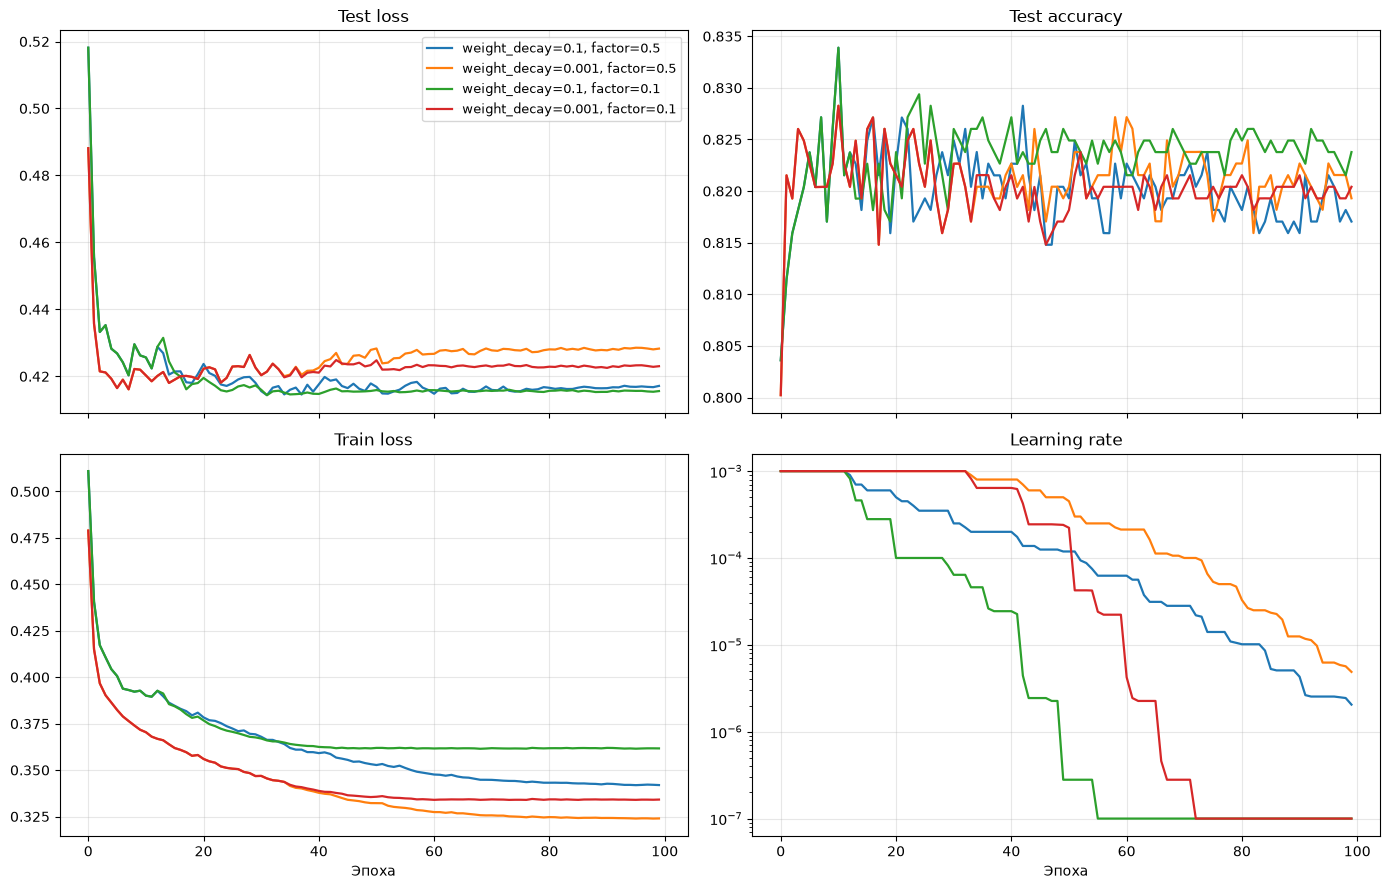

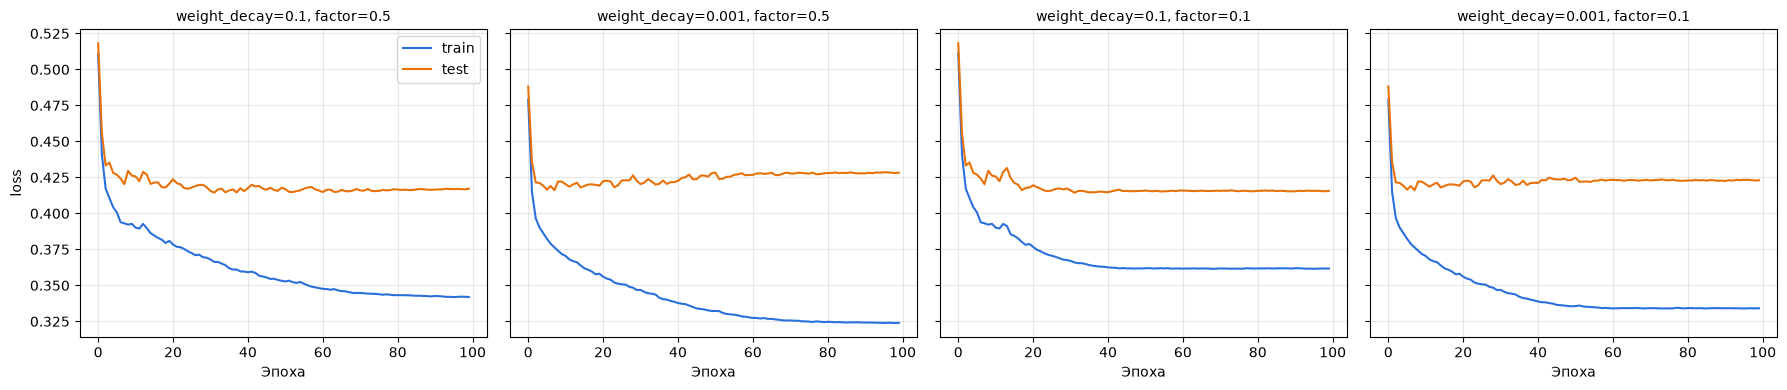

In [46]:
dl_curves = pd.DataFrame(dl_curves)

combos = list(dl_curves['combo'].unique())      # порядок появления
colors = plt.cm.tab10.colors

# среднее по фолдам для каждой комбинации
curve = dl_curves.groupby(['combo', 'epoch']).mean(numeric_only=True).reset_index()

# --- 1) Сравнение комбинаций на одних осях ---
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
panels = [
    ('test_loss',     'Test loss'),
    ('test_accuracy', 'Test accuracy'),
    ('train_loss',    'Train loss'),
    ('lr',            'Learning rate'),
]
for ax, (col, title) in zip(axes.ravel(), panels):
    for color, name in zip(colors, combos):
        d = curve[curve['combo'] == name]
        ax.plot(d['epoch'], d[col], color=color, label=name, lw=1.6)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    if col == 'lr':
        ax.set_yscale('log')
for ax in axes[1]:
    ax.set_xlabel('Эпоха')
axes[0, 0].legend(fontsize=9)
plt.tight_layout()
plt.show()

# --- 2) Отдельная картинка на комбинацию: train vs test ---
fig, axes = plt.subplots(1, len(combos), figsize=(4.5 * len(combos), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, name in zip(axes, combos):
    d = curve[curve['combo'] == name]
    ax.plot(d['epoch'], d['train_loss'], color='#2a6fdb', label='train')
    ax.plot(d['epoch'], d['test_loss'],  color='#e8710a', label='test')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Эпоха')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('loss')
axes[0].legend()
plt.tight_layout()
plt.show()